In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [24]:
data = pd.read_csv("sales_data_sample.csv", encoding="ISO-8859-1")

print("Dataset Loaded Successfully!")
print(data.head())
print("Dataset Shape:", data.shape)

Dataset Loaded Successfully!
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 

In [25]:
X = data[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]

print("Selected Features:")
print(X.head())

Selected Features:
   QUANTITYORDERED  PRICEEACH    SALES
0               30      95.70  2871.00
1               34      81.35  2765.90
2               41      94.74  3884.34
3               45      83.26  3746.70
4               49     100.00  5205.27


In [26]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data Normalized Successfully!")

Data Normalized Successfully!


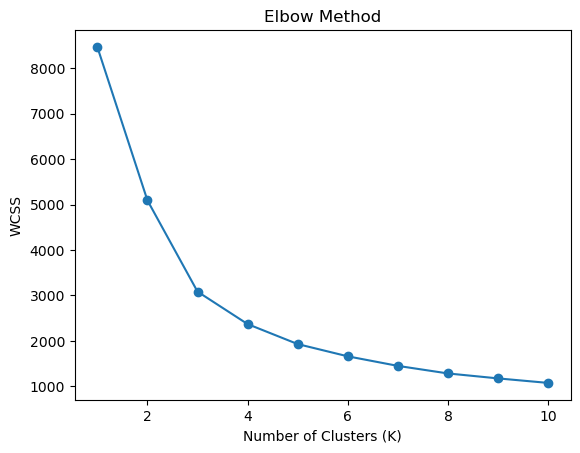

In [27]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.show()

In [28]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_pred = kmeans.fit_predict(X_scaled)

data['Cluster'] = y_pred

print("K-Means Clustering Completed!")
print(data[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'Cluster']].head())

K-Means Clustering Completed!
   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        1
4               49     100.00  5205.27        1


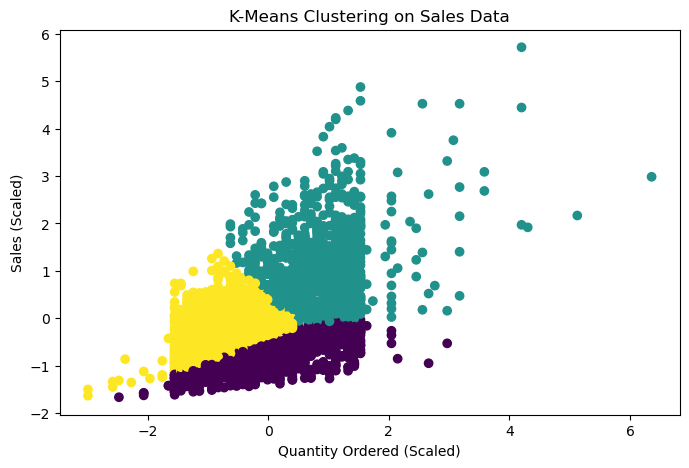

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=y_pred,
    cmap='viridis'
)

plt.title("K-Means Clustering on Sales Data")
plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")
plt.show()

In [30]:
print("Number of Clusters:", len(set(y_pred)))

print("\nCluster Distribution:")
print(data['Cluster'].value_counts().sort_index())

print("\nCluster Centers:")
print(scaler.inverse_transform(kmeans.cluster_centers_))

Number of Clusters: 3

Cluster Distribution:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64

Cluster Centers:
[[  35.12599319   57.13021566 2009.8299546 ]
 [  43.84361233   96.62390969 5581.55927313]
 [  27.38007737   94.87605416 3088.89056093]]
